In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [20]:
df = pd.read_csv('titanic.csv')
#print(df.head())

In [21]:
print(df.shape)
print(df.columns)


(891, 12)
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


Missing Values

In [23]:
df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [24]:
df.drop('Cabin',axis=1,inplace=True)

In [25]:
df['Age'].fillna(df['Age'].mean(),inplace=True)
print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Embarked  
0      0         A/5 21171   7.2500        S  
1      0          PC 17599  71.2833        C  
2      0  STON/O2. 3101282   7.9250        S  
3      0            113803  53.1000        S  
4      0            373450   8.0500        S  


/tmp/ipykernel_4405/1253644116.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean(),inplace=True)


Dead or Alive

In [26]:
sur = { 0 : "alive", 1 : 'dead' }
df['status'] = df['Survived'].map(sur)
df['status'].value_counts()

,count
status,
alive,549
dead,342


In [29]:
df.groupby('Sex')['status'].value_counts()


Pclass  status
1       dead      136
        alive      80
2       alive      97
        dead       87
3       alive     372
        dead      119
Name: count, dtype: int64

In [30]:
df.groupby('Pclass')['status'].value_counts()

Pclass  status
1       dead      136
        alive      80
2       alive      97
        dead       87
3       alive     372
        dead      119
Name: count, dtype: int64

In [33]:
print(f"the average age {df['Age'].mean()} and average fare {df['Fare'].mean()}")

the average age 29.69911764705882 and average fare 32.204207968574636


Visualization

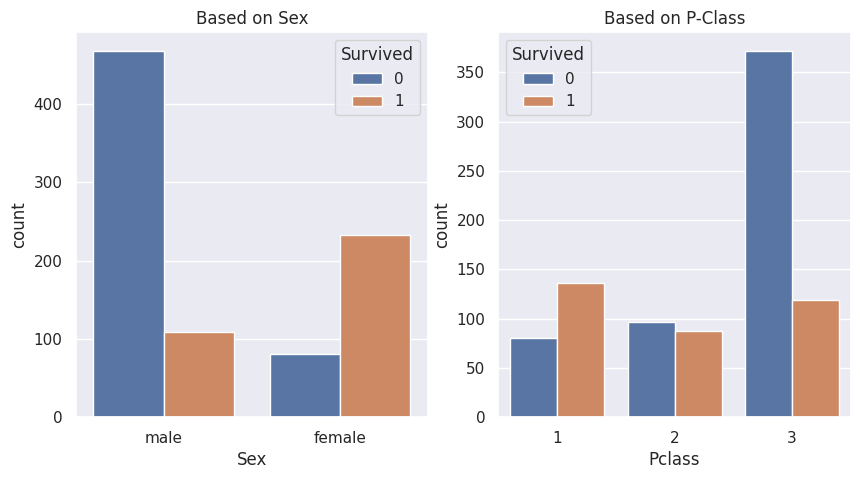

In [52]:
plt.figure(figsize=(10,5))
sns.set_theme(style='darkgrid')
plt.subplot(1,2,1)
plt.title("Based on Sex")
sns.countplot(data=df,x='Sex',hue='Survived')
plt.subplot(1,2,2)
sns.countplot(data=df,x='Pclass',hue='Survived')
plt.title("Based on P-Class")
plt.show()

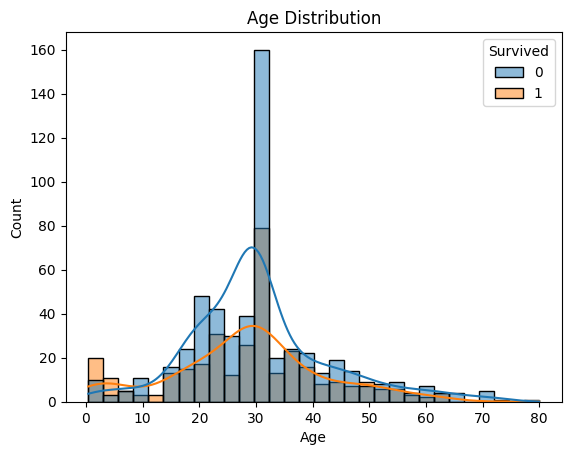

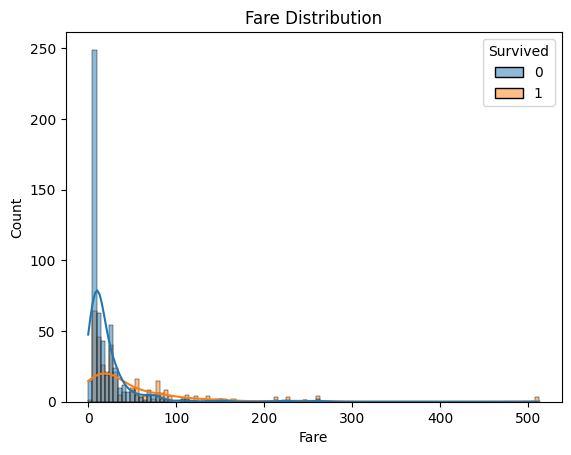

In [50]:
sns.histplot(data=df,x='Age',hue='Survived',kde=True)
plt.title("Age Distribution")
plt.show()
sns.histplot(data=df,x='Fare',hue='Survived',kde=True)
plt.title("Fare Distribution")
plt.show()